# 01 · Experiments

Guide sections 6–10. Orchestration only: train with `train(load_config(...))`, evaluate with your `evaluate`, look at videos and curves. Each experiment gets its own config in `configs/`.

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
ROOT = Path.cwd().resolve()

while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
print("repo root:", ROOT, "| colab:", IN_COLAB)

repo root: D:\Code\push-t | colab: False


In [2]:
if IN_COLAB:
    %pip install -q -e "{ROOT}[dev]"

In [2]:
import json
import subprocess

from IPython.display import Image, Video, display

from pusht_bc.config import load_config, resolve_path
from pusht_bc.evaluate import build_agent_from_checkpoint, format_summary, run_and_save
from pusht_bc.train import save_train_outputs, train
from pusht_bc.utils import checkpoint_path, get_device, plot_coverage_over_time, plot_losses, run_dir

DEVICE = get_device()
print("device:", DEVICE)

device: cpu


## 1 · Feature cache

Runs once (needs your `Normalizer`, guide section 3). Writes `data/cache/features_resnet18.pt`.

In [4]:
cache = resolve_path("data/cache/features_resnet18.pt")
if not cache.exists():
    proc = subprocess.run([sys.executable, str(ROOT / "scripts" / "cache_features.py")], cwd=ROOT, capture_output=True, text=True)
    print(proc.stdout[-2000:], proc.stderr[-2000:])
    proc.check_returncode()
    
print(cache, cache.exists())

D:\Code\push-t\data\cache\features_resnet18.pt True


## 2 · Helpers: evaluate and show

In [4]:
def eval_checkpoint(ckpt_path, cfg, seeds=None, record_seeds=None, out_dir=None):
    """
    Evaluate a checkpoint with your evaluate() and save summary, videos and coverage plot.

    Args:
        ckpt_path: checkpoint file.
        cfg: its Config (seeds and max_steps come from cfg.eval unless given).
        seeds: env seeds (default: dev seeds).
        record_seeds: seeds to record (default: cfg.eval.record_seeds).
        out_dir: output folder (default: <run>/eval/<checkpoint name>).
    Returns:
        EvalSummary.
    """
    seeds = cfg.eval.dev_seed_list() if seeds is None else seeds
    record_seeds = cfg.eval.record_seeds if record_seeds is None else record_seeds
    ckpt_path = Path(ckpt_path)
    out_dir = out_dir or run_dir(cfg) / "eval" / ckpt_path.stem
    agent = build_agent_from_checkpoint(ckpt_path, DEVICE)
    summary = run_and_save(agent, seeds, record_seeds, out_dir, cfg.eval.max_steps, label=f"{cfg.name}/{ckpt_path.stem}")
    summary.out_dir = Path(resolve_path(out_dir))

    return summary

def show_eval(summary, label=""):
    """
    Print a summary and show its recorded videos and coverage plot inline.

    Args:
        summary: EvalSummary returned by eval_checkpoint or run_and_save.
        label: name to print.
    """
    print(format_summary(summary, label))

    out = getattr(summary, "out_dir", None)
    if out is None:
        return
    
    for ep in summary.episodes:
        video = out / f"seed_{ep.seed}.mp4"
        if video.exists():
            print(f"seed {ep.seed}: success={ep.success} max_coverage={ep.max_coverage:.3f} steps={ep.steps}")
            display(Video(str(video), embed=True, width=320))

    if (out / "coverage.png").exists():
        display(Image(str(out / "coverage.png")))

## 3 · Sanity check: pretrained Diffusion Policy through your loop

Guide section 7. Expect roughly 50–75% on seeds 0–49. Slow on CPU; use a GPU.

In [6]:
RUN_DP = False  # set True to run (minutes on GPU, hours on CPU)
if RUN_DP:
    from pusht_bc.policies.pretrained_dp import PretrainedDiffusionAgent

    dp_agent = PretrainedDiffusionAgent(device=DEVICE)
    dp_out = resolve_path("runs/diffusion_pusht/eval")
    dp_summary = run_and_save(dp_agent, list(range(50)), [0, 1, 2], dp_out, 300, label="diffusion_pusht")
    dp_summary.out_dir = dp_out
    show_eval(dp_summary, "diffusion_pusht")

## 4 · Plots: loss curves and coverage over time

In [5]:
def show_losses(cfg):
    """
    Plot the loss curves saved in <run>/history.json.

    Args:
        cfg: Config of the run.
    """
    hist = json.loads((run_dir(cfg) / "history.json").read_text())["history"]
    display(Image(str(plot_losses(hist, run_dir(cfg) / "losses.png"))))

def show_coverage(summary, seeds, path):
    """
    Plot coverage over time for some seeds of a summary.

    Args:
        summary: EvalSummary.
        seeds: seeds to plot.
        path: output .png file.
    """
    curves = {f"seed {e.seed} ({'success' if e.success else 'fail'})": e.rewards for e in summary.episodes if e.seed in seeds}
    display(Image(str(plot_coverage_over_time(curves, path))))

## E1 · Plain behavior cloning (v0)

Prediction (write it before running):

Result:

In [8]:
CONFIG_E1 = ROOT / "configs/bc_v0.yaml"
TRAIN_E1 = False

In [9]:
if CONFIG_E1 is not None:
    cfg_E1 = load_config(CONFIG_E1)
    
if CONFIG_E1 is not None and TRAIN_E1:
    result_E1 = train(cfg_E1)
    save_train_outputs(cfg_E1, result_E1)
    print("best val loss:", result_E1.best_val_loss)

bc_v0: success 0.0% (95% CI 0.0%-7.1%, n=50), avg max coverage 0.103
seed 0: success=False max_coverage=0.280 steps=300


seed 1: success=False max_coverage=0.000 steps=300


seed 2: success=False max_coverage=0.000 steps=300


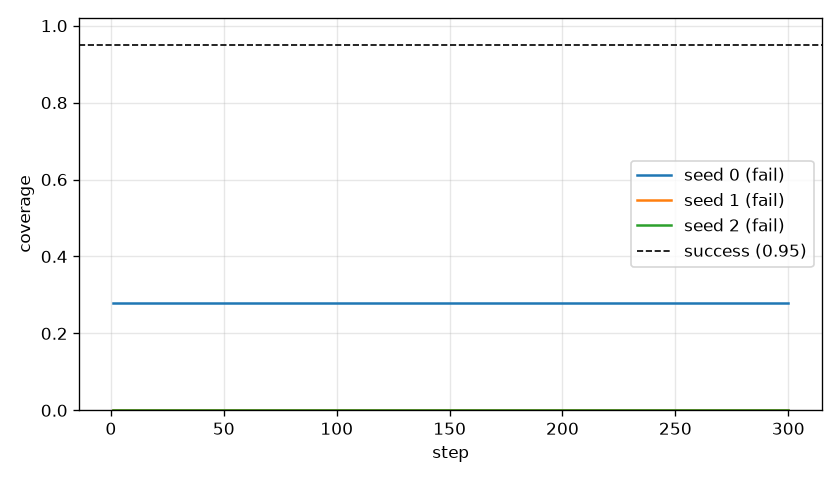

In [10]:
if CONFIG_E1 is not None:
    summary_E1 = eval_checkpoint(checkpoint_path(cfg_E1, cfg_E1.epochs), cfg_E1)
    show_eval(summary_E1, cfg_E1.name)

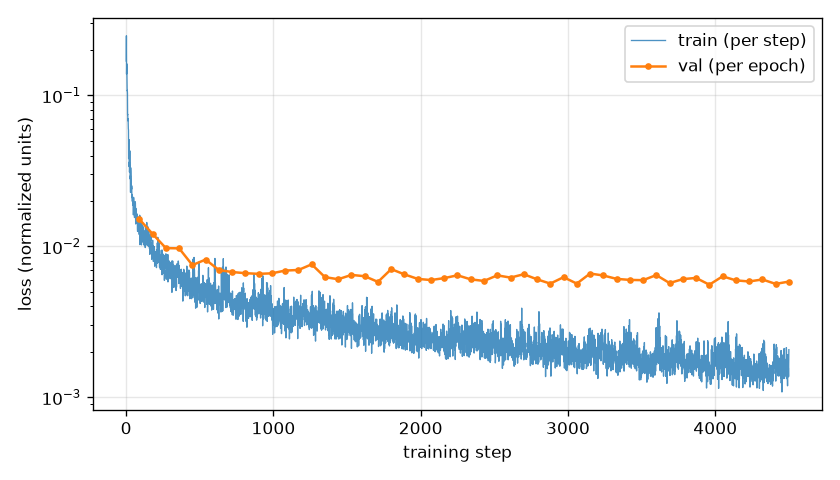

In [ ]:
if CONFIG_E1 is not None:
    show_losses(cfg_E1)

## E2 · Does lower validation loss mean higher success? (evaluate epochs 5, 10, 25, 50)

Prediction (write it before running):

Result:

In [6]:
CONFIG_E2 = ROOT / "configs/bc_v0.yaml"  # E2 reuses the v0 run: no new training
TRAIN_E2 = False
E2_EPOCHS = [5, 10, 25, 50]

In [7]:
if CONFIG_E2 is not None:
    cfg_E2 = load_config(CONFIG_E2)
    
if CONFIG_E2 is not None and TRAIN_E2:
    result_E2 = train(cfg_E2)
    save_train_outputs(cfg_E2, result_E2)
    print("best val loss:", result_E2.best_val_loss)

In [8]:
if CONFIG_E2 is not None:
    summaries_E2 = {}
    for ep in E2_EPOCHS:
        # record_seeds=[]: no videos, only summary.json in runs/bc_v0/eval/epoch_0XX/
        summaries_E2[ep] = eval_checkpoint(checkpoint_path(cfg_E2, ep), cfg_E2, record_seeds=[])
        print(f"epoch {ep}:", format_summary(summaries_E2[ep]))

epoch 5: success 0.0% (95% CI 0.0%-7.1%, n=50), avg max coverage 0.098
epoch 10: success 0.0% (95% CI 0.0%-7.1%, n=50), avg max coverage 0.103
epoch 25: success 0.0% (95% CI 0.0%-7.1%, n=50), avg max coverage 0.121
epoch 50: success 0.0% (95% CI 0.0%-7.1%, n=50), avg max coverage 0.103


In [9]:
if CONFIG_E2 is not None:
    hist_E2 = json.loads((run_dir(cfg_E2) / "history.json").read_text())["history"]
    val_loss_E2 = {ep: hist_E2["val_loss"][ep - 1] for ep in E2_EPOCHS}
    # TODO: plot val_loss_E2[ep] against summaries_E2[ep].success_rate and .avg_max_coverage,
    # save it to run_dir(cfg_E2) / "e2_val_vs_success.png"

## E3 · How much does more data help? (25%, 50%, 100% of training episodes)

Prediction (write it before running):

Result:

In [ ]:
CONFIG_E3 = None  # e.g. ROOT / "configs/e3_....yaml"
TRAIN_E3 = True  # False: only evaluate an existing run

In [ ]:
if CONFIG_E3 is not None:
    cfg_E3 = load_config(CONFIG_E3)
if CONFIG_E3 is not None and TRAIN_E3:
    result_E3 = train(cfg_E3)
    save_train_outputs(cfg_E3, result_E3)
    print("best val loss:", result_E3.best_val_loss)

In [ ]:
if CONFIG_E3 is not None:
    summary_E3 = eval_checkpoint(checkpoint_path(cfg_E3, cfg_E3.epochs), cfg_E3)
    show_eval(summary_E3, cfg_E3.name)

## E4 · Does a trainable encoder help? (end to end, 84×84 crops)

Prediction (write it before running):

Result:

In [ ]:
CONFIG_E4 = None  # e.g. ROOT / "configs/e4_....yaml"
TRAIN_E4 = True  # False: only evaluate an existing run

In [ ]:
if CONFIG_E4 is not None:
    cfg_E4 = load_config(CONFIG_E4)
if CONFIG_E4 is not None and TRAIN_E4:
    result_E4 = train(cfg_E4)
    save_train_outputs(cfg_E4, result_E4)
    print("best val loss:", result_E4.best_val_loss)

In [ ]:
if CONFIG_E4 is not None:
    summary_E4 = eval_checkpoint(checkpoint_path(cfg_E4, cfg_E4.epochs), cfg_E4)
    show_eval(summary_E4, cfg_E4.name)

## E5 · Does L1 change behavior?

Prediction (write it before running):

Result:

In [ ]:
CONFIG_E5 = None  # e.g. ROOT / "configs/e5_....yaml"
TRAIN_E5 = True  # False: only evaluate an existing run

In [ ]:
if CONFIG_E5 is not None:
    cfg_E5 = load_config(CONFIG_E5)
if CONFIG_E5 is not None and TRAIN_E5:
    result_E5 = train(cfg_E5)
    save_train_outputs(cfg_E5, result_E5)
    print("best val loss:", result_E5.best_val_loss)

In [ ]:
if CONFIG_E5 is not None:
    summary_E5 = eval_checkpoint(checkpoint_path(cfg_E5, cfg_E5.epochs), cfg_E5)
    show_eval(summary_E5, cfg_E5.name)

## E6 · Are deltas easier than absolute targets?

Prediction (write it before running):

Result:

In [ ]:
CONFIG_E6 = None  # e.g. ROOT / "configs/e6_....yaml"
TRAIN_E6 = True  # False: only evaluate an existing run

In [ ]:
if CONFIG_E6 is not None:
    cfg_E6 = load_config(CONFIG_E6)
if CONFIG_E6 is not None and TRAIN_E6:
    result_E6 = train(cfg_E6)
    save_train_outputs(cfg_E6, result_E6)
    print("best val loss:", result_E6.best_val_loss)

In [ ]:
if CONFIG_E6 is not None:
    summary_E6 = eval_checkpoint(checkpoint_path(cfg_E6, cfg_E6.epochs), cfg_E6)
    show_eval(summary_E6, cfg_E6.name)

## E7 · Action chunking (K = 8, n_execute = 4)

Prediction (write it before running):

Result:

In [ ]:
CONFIG_E7 = None  # e.g. ROOT / "configs/e7_....yaml"
TRAIN_E7 = True  # False: only evaluate an existing run

In [ ]:
if CONFIG_E7 is not None:
    cfg_E7 = load_config(CONFIG_E7)
if CONFIG_E7 is not None and TRAIN_E7:
    result_E7 = train(cfg_E7)
    save_train_outputs(cfg_E7, result_E7)
    print("best val loss:", result_E7.best_val_loss)

In [ ]:
if CONFIG_E7 is not None:
    summary_E7 = eval_checkpoint(checkpoint_path(cfg_E7, cfg_E7.epochs), cfg_E7)
    show_eval(summary_E7, cfg_E7.name)